@@TITULO@@

@@PROBLEMA@@

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)

raiz = Path.cwd()
while not (raiz / "data").exists() and raiz != raiz.parent:
    raiz = raiz.parent
d = pd.read_csv(raiz / "data" / "processed" / "linha3_10min.csv", parse_dates=["t"]).set_index("t")
ar = pd.read_csv(raiz / "data" / "processed" / "clima_10min.csv", parse_dates=["t"]).set_index("t")
d = d.join(ar.drop(columns=["temp_ar", "umid_ar", "vpd_kpa"]))
print(f"{len(d)} linhas de 10 minutos,", d.fase.eq("controle").sum(), "na fase de controle")

26928 linhas de 10 minutos, 8256 na fase de controle


In [2]:
HORIZONTE = 6      # o alvo olha 6 passos de 10 min = 1 hora para a frente
ESPERA = 12        # depois de uma rega, 12 passos (2 h) sem decisão, até o solo assentar

def preparar(g):
    g = g.copy()
    v = g.valvula.astype(int).to_numpy()
    inicio, fechada = np.zeros(len(g), bool), 99
    for i, x in enumerate(v):
        if x == 1 and fechada >= 6:            # válvula abriu depois de pelo menos 1 h fechada = rega nova
            inicio[i] = True
        fechada = 0 if x == 1 else fechada + 1
    g["inicio"] = inicio
    g["y"] = g.inicio[::-1].rolling(HORIZONTE, min_periods=1).max()[::-1].shift(-1).fillna(0).astype(int)     # alguma rega começa nos próximos 60 min
    ultima = g.index.to_series().where(g.inicio).ffill()
    g["h_desde_rega"] = (g.index.to_series() - ultima).dt.total_seconds() / 3600
    # a umidade do solo de duas formas que não olham a válvula: padronizada e min-max dentro da fase de controle do ano
    c = g[g.fase == "controle"].umid_solo_15cm
    g["umid_z"] = (g.umid_solo_15cm - c.mean()) / c.std()
    lo, hi = c.quantile([.05, .95])
    g["umid_minmax"] = (g.umid_solo_15cm - lo) / (hi - lo)
    return g

D = pd.concat([preparar(g) for _, g in d.groupby("ano")])
D["hora_sin"] = np.sin(2 * np.pi * D.hora_local / 24)
D["hora_cos"] = np.cos(2 * np.pi * D.hora_local / 24)

# variáveis do ar, por grupo (as colunas vêm de clima_10min.csv)
GRUPOS = {
    "medida na fazenda": ["temp_ar", "umid_ar", "vpd_kpa", "vpd_3h"],
    "calculada com a fazenda": ["et0_pm_local", "et0_pm_local_3h", "et0_hargreaves_dia_anterior"],
    "Open-Meteo": ["om_et0", "om_et0_3h", "om_radiacao", "om_radiacao_direta", "om_radiacao_difusa", "om_vento", "om_rajada", "om_nuvens",
                   "om_vpd", "om_temp", "om_ur", "om_orvalho", "om_pressao", "om_chuva", "om_solo_temp", "om_solo_umid"],
    "relógio": ["hora_sin", "hora_cos"],
}
TODAS = [c for lista in GRUPOS.values() for c in lista]

c = D[D.fase == "controle"]
valido = (~c.buraco) & (~c.chuva_suspeita) & (~c.valvula) & (c.h_desde_rega.fillna(99) > ESPERA / 6)
valido &= c[["u_15cm", "umid_solo_15cm", "umid_z", "umid_minmax"] + TODAS].notna().all(axis=1)     # as mesmas linhas para todos os candidatos
C = c[valido]
contagem = pd.DataFrame({"linhas da fase de controle": c.groupby("ano").size(), "usadas": C.groupby("ano").size(),
                         "regas na fase": c.groupby("ano").inicio.sum(), "linhas com alvo = 1": C.groupby("ano").y.sum()})
contagem["% com alvo = 1"] = (100 * contagem["linhas com alvo = 1"] / contagem["usadas"]).round(1)
contagem

,linhas da fase de controle,usadas,regas na fase,linhas com alvo = 1,% com alvo = 1
ano,,,,,
2024,4320,3279,38,186,5.7
2025,3936,2940,53,301,10.2


@@AVALIAR@@

In [3]:
def melhor_corte(y, s):
    p, r, cortes = precision_recall_curve(y, s)
    f = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-9)
    return cortes[np.argmax(f)]

def avaliar(colunas):
    # treina em um ano, testa no outro, nos dois sentidos. O corte vem só do ano de treino.
    saida = []
    for treino, teste in ((2024, 2025), (2025, 2024)):
        A, B = C[C.ano == treino], C[C.ano == teste]
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")).fit(A[colunas], A.y)
        sA, sB = m.predict_proba(A[colunas])[:, 1], m.predict_proba(B[colunas])[:, 1]
        alarme = sB >= melhor_corte(A.y, sA)
        tp, fp, fn = (alarme & (B.y == 1)).sum(), (alarme & (B.y == 0)).sum(), ((~alarme) & (B.y == 1)).sum()
        saida.append({"ap": average_precision_score(B.y, sB), "prec": tp / max(tp + fp, 1), "sens": tp / max(tp + fn, 1), "alarme": alarme.mean()})
    return saida

def resumo(nome, colunas, grupo=""):
    a, b = avaliar(colunas)
    return {"grupo": grupo, "entradas": nome, "AP 2024→2025": round(a["ap"], 2), "AP 2025→2024": round(b["ap"], 2),
            "AP médio": round((a["ap"] + b["ap"]) / 2, 2), "precisão média": round((a["prec"] + b["prec"]) / 2, 2),
            "sensibilidade média": round((a["sens"] + b["sens"]) / 2, 2)}

@@UMIDADE_INTRO@@

In [4]:
# a umidade do solo de quatro formas, com um exemplo de variável do ar (o VPD medido na fazenda)
linhas = []
for nome, col in (("bruta (% do sensor)", "umid_solo_15cm"), ("padronizada por ano (z)", "umid_z"),
                  ("min-max por ano (percentis 5 e 95)", "umid_minmax"), ("índice u (FAO-56)", "u_15cm")):
    solo = avaliar([col])
    com_vpd = avaliar([col, "vpd_kpa"])
    linhas.append({"umidade do solo": nome, "AP só o solo": round(np.mean([x["ap"] for x in solo]), 2),
                   "AP com VPD": round(np.mean([x["ap"] for x in com_vpd]), 2),
                   "2024→2025: precisão": round(com_vpd[0]["prec"], 2), "sens.": round(com_vpd[0]["sens"], 2), "em alarme": f"{com_vpd[0]['alarme']:.0%}",
                   "2025→2024: precisão ": round(com_vpd[1]["prec"], 2), "sens. ": round(com_vpd[1]["sens"], 2), "em alarme ": f"{com_vpd[1]['alarme']:.0%}"})
pd.DataFrame(linhas).set_index("umidade do solo")

,AP só o solo,AP com VPD,2024→2025: precisão,sens.,em alarme,2025→2024: precisão,sens.,em alarme
umidade do solo,,,,,,,,
bruta (% do sensor),0.49,0.55,0.00,0.00,0%,0.06,1.00,99%
padronizada por ano (z),0.49,0.58,0.70,0.56,8%,0.30,0.92,17%
min-max por ano (percentis 5 e 95),0.49,0.59,0.61,0.84,14%,0.39,0.62,9%
índice u (FAO-56),0.49,0.60,0.70,0.59,9%,0.34,0.88,15%


@@UMIDADE_LEITURA@@

@@AR_INTRO@@

In [5]:
NOMES = {"temp_ar": "temperatura do ar", "umid_ar": "umidade do ar", "vpd_kpa": "VPD", "vpd_3h": "VPD, média de 3 h",
         "et0_pm_local": "ET₀ Penman-Monteith (fazenda + radiação e vento do Open-Meteo)", "et0_pm_local_3h": "ET₀ Penman-Monteith, média de 3 h",
         "et0_hargreaves_dia_anterior": "ET₀ Hargreaves (temperatura, dia anterior)",
         "om_et0": "ET₀", "om_et0_3h": "ET₀, soma de 3 h", "om_radiacao": "radiação", "om_radiacao_direta": "radiação direta", "om_radiacao_difusa": "radiação difusa",
         "om_vento": "vento", "om_rajada": "rajada de vento", "om_nuvens": "nuvens", "om_vpd": "VPD", "om_temp": "temperatura", "om_ur": "umidade",
         "om_orvalho": "ponto de orvalho", "om_pressao": "pressão", "om_chuva": "chuva", "om_solo_temp": "temperatura do solo (0 a 7 cm)",
         "om_solo_umid": "umidade do solo (0 a 7 cm)", "hora_sin": "hora do dia (seno)", "hora_cos": "hora do dia (cosseno)"}

linhas = [resumo("só o solo (sem variável do ar)", ["u_15cm"], "referência")]
for grupo, lista in GRUPOS.items():
    if grupo == "relógio":
        continue
    for col in lista:
        linhas.append(resumo(NOMES[col], ["u_15cm", col], grupo))
PARES = [("VPD e VPD, média de 3 h", ["vpd_kpa", "vpd_3h"], "medida na fazenda"),
         ("temperatura e umidade do ar", ["temp_ar", "umid_ar"], "medida na fazenda"),
         ("ET₀ Penman-Monteith e VPD", ["et0_pm_local", "vpd_kpa"], "calculada com a fazenda"),
         ("ET₀ Penman-Monteith e ET₀, média de 3 h", ["et0_pm_local", "et0_pm_local_3h"], "calculada com a fazenda"),
         ("radiação e vento", ["om_radiacao", "om_vento"], "Open-Meteo"),
         ("hora do dia (seno e cosseno)", ["hora_sin", "hora_cos"], "relógio"),
         ("hora do dia e VPD", ["hora_sin", "hora_cos", "vpd_kpa"], "relógio")]
for nome, cols, grupo in PARES:
    linhas.append(resumo(nome, ["u_15cm"] + cols, grupo))
tabela = pd.DataFrame(linhas).sort_values("AP médio", ascending=False).reset_index(drop=True)
tabela

,grupo,entradas,AP 2024→2025,AP 2025→2024,AP médio,precisão média,sensibilidade média
0,medida na fazenda,"VPD e VPD, média de 3 h",0.88,0.45,0.67,0.66,0.74
1,relógio,hora do dia e VPD,0.87,0.44,0.66,0.66,0.76
2,calculada com a fazenda,ET₀ Penman-Monteith e VPD,0.78,0.46,0.62,0.58,0.73
3,medida na fazenda,temperatura e umidade do ar,0.79,0.42,0.61,0.54,0.75
4,medida na fazenda,temperatura do ar,0.80,0.42,0.61,0.56,0.72
5,medida na fazenda,VPD,0.78,0.42,0.60,0.52,0.73
6,medida na fazenda,umidade do ar,0.77,0.40,0.58,0.48,0.78
7,calculada com a fazenda,"ET₀ Penman-Monteith, média de 3 h",0.74,0.42,0.58,0.45,0.79
8,calculada com a fazenda,ET₀ Penman-Monteith (fazenda + radiação e vent...,0.73,0.44,0.58,0.50,0.73
9,calculada com a fazenda,"ET₀ Penman-Monteith e ET₀, média de 3 h",0.73,0.44,0.58,0.49,0.75


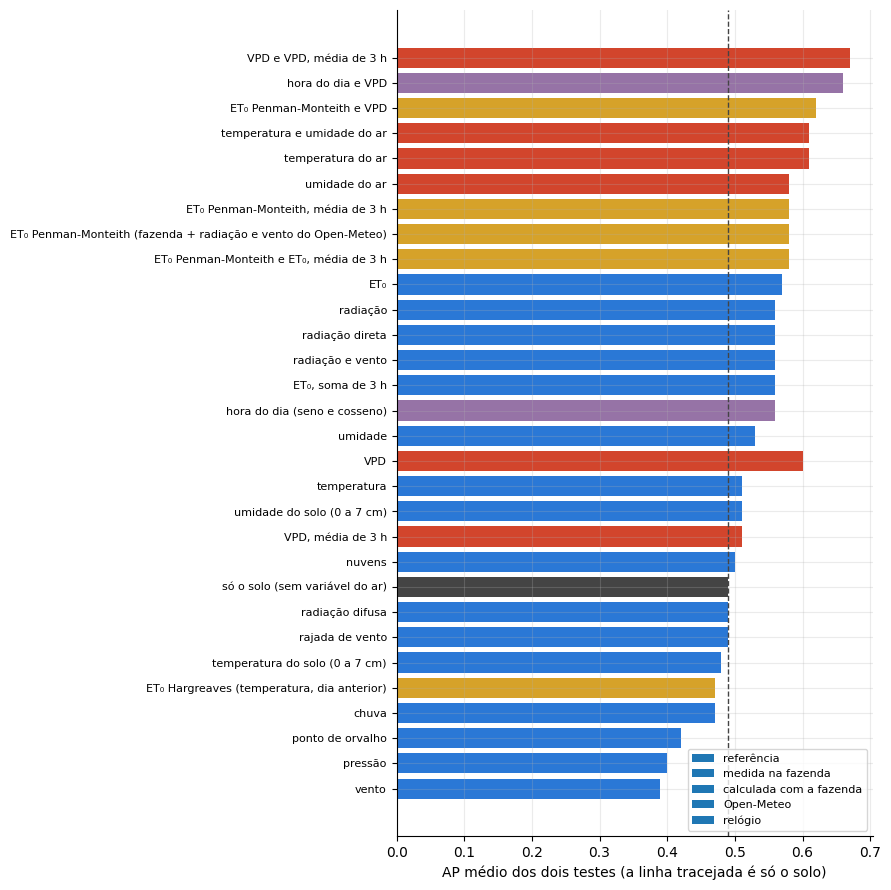

In [6]:
cores = {"referência": "#444444", "medida na fazenda": "#d2452c", "calculada com a fazenda": "#d6a229", "Open-Meteo": "#2a78d6", "relógio": "#9673a6"}
t = tabela.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 9))
ax.barh([f"{e}" for e in t.entradas], t["AP médio"], color=[cores[g] for g in t.grupo])
ax.axvline(float(tabela.loc[tabela.grupo == "referência", "AP médio"].iloc[0]), color="#444", lw=1, ls="--")
for g, cor in cores.items():
    ax.barh([], [], color=cor, label=g)
ax.set_xlabel("AP médio dos dois testes (a linha tracejada é só o solo)"); ax.legend(fontsize=8, loc="lower right")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

@@AR_LEITURA@@

@@LIMITES@@